In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RESULTS = Path("..") / "results" / "timings.csv"
df = pd.read_csv(RESULTS)

# Per-operation cost: every row is a batch of n_ops operations.
df["us_per_op"] = df["total_ns"] / df["n_ops"] / 1_000 # The microseconds one operation took
for counter in ["comparisons", "nodes_visited", "rotations", "splits", "resizes"]:
    df[f"{counter}_per_op"] = df[counter] / df["n_ops"]

df[["experiment", "index_type", "operation", "operation_param", "us_per_op",
    "comparisons_per_op", "nodes_visited_per_op"]].head()

,experiment,index_type,operation,operation_param,us_per_op,comparisons_per_op,nodes_visited_per_op
0,CORE,unsorted_list,build,NaN,0.122900,0.0,0.0
1,CORE,unsorted_list,build,NaN,0.111384,0.0,0.0
2,CORE,unsorted_list,point_hit,NaN,3924.546877,114000.0,0.0
3,CORE,unsorted_list,point_miss,NaN,3811.619044,114000.0,0.0
4,CORE,unsorted_list,range,0.01,3680.383540,114000.0,0.0


In [2]:
mine = df[df["machine_id"] == "shreya-mbp"]

e3 = mine[mine["experiment"] == "E3_range_tempo"].copy()
e4 = mine[mine["experiment"] == "E4_prefix_track_name"].copy()

print("E3 rows:", len(e3), "| E4 rows:", len(e4))
print(e3.groupby("code_version").size())
print(e4.groupby("code_version").size())

E3 rows: 210 | E4 rows: 175
code_version
e7b23fd    210
dtype: int64
code_version
e7b23fd    175
dtype: int64


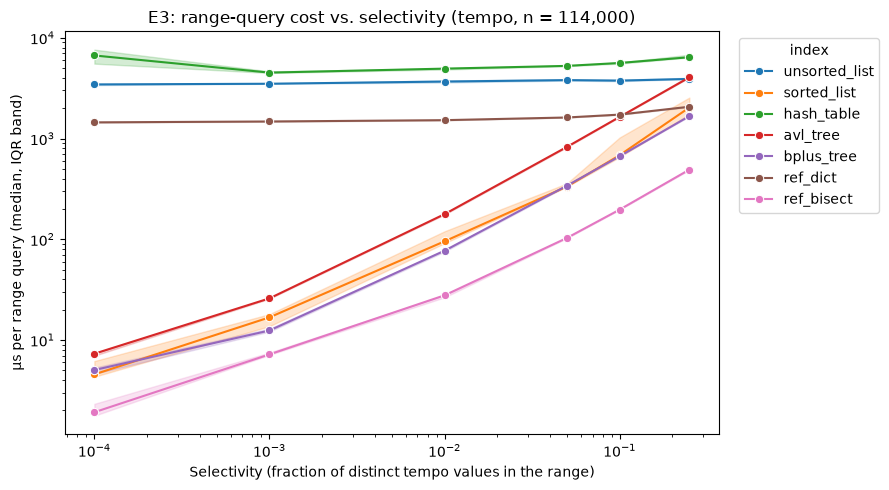

In [4]:
plt.figure(figsize=(9, 5))
sns.lineplot(
    data=e3, x="operation_param", y="us_per_op", hue="index_type",
    estimator="median", errorbar=("pi", 50), marker="o",
)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Selectivity (fraction of distinct tempo values in the range)")
plt.ylabel("µs per range query (median, IQR band)")
plt.title("E3: range-query cost vs. selectivity (tempo, n = 114,000)")
plt.legend(title="index", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("e3_range.png", dpi=150)
plt.show()

In [5]:
rows = []
for idx, g in e3.groupby("index_type"):
    # median time per query at each selectivity
    med = g.groupby("operation_param")["us_per_op"].median()

    # slope across all 6 selectivities
    slope_all, _ = np.polyfit(np.log10(med.index), np.log10(med.values), 1)

    # slope for the larger ranges only (0.01 and up)
    big = med[med.index >= 0.01]
    slope_big, _ = np.polyfit(np.log10(big.index), np.log10(big.values), 1)

    rows.append({"index": idx,
                 "slope_all": round(slope_all, 2),
                 "slope_0.01_and_up": round(slope_big, 2)})

e3_slopes = pd.DataFrame(rows).sort_values("slope_all")
e3_slopes

,index,slope_all,slope_0.01_and_up
2,hash_table,0.00,0.08
6,unsorted_list,0.02,0.02
4,ref_dict,0.04,0.09
3,ref_bisect,0.70,0.89
1,bplus_tree,0.76,0.95
5,sorted_list,0.77,0.94
0,avl_tree,0.82,0.97


In [6]:
counters = (
    e3.groupby(["index_type", "operation_param"])[["comparisons_per_op", "nodes_visited_per_op", "us_per_op"]]
      .median()
      .round(1)
      .unstack("operation_param")
)
counters

comparisons_per_op                                          \
operation_param             0.0001    0.0010    0.0100    0.0500    0.1000   
index_type                                                                   
avl_tree                      20.1      61.2     472.0    2297.8    4579.5   
bplus_tree                    28.5      69.6     480.6    2306.5    4588.3   
hash_table                 45653.0   45653.0   45653.0   45653.0   45653.0   
ref_bisect                     NaN       NaN       NaN       NaN       NaN   
ref_dict                       NaN       NaN       NaN       NaN       NaN   
sorted_list                   21.5      62.5     473.5    2299.5    4581.6   
unsorted_list             114000.0  114000.0  114000.0  114000.0  114000.0   

                          nodes_visited_per_op                             \
operation_param    0.2500               0.0001   0.0010   0.0100   0.0500   
index_type                                                                  
avl_tree          11427.4                 20.1     61.2    472.0   2297.8   
bplus_tree        11436.5                  4.2      6.1     25.0    109.0   
hash_table        45653.0              61448.0  61448.0  61448.0  61448.0   
ref_bisect            NaN                  NaN      NaN      NaN      NaN   
ref_dict              NaN                  NaN      NaN      NaN      NaN   
sorted_list       11429.6                  0.0      0.0      0.0      0.0   
unsorted_list    114000.0                  0.0      0.0      0.0      0.0   

                                  us_per_op                                  \
operation_param   0.1000   0.2500    0.0001  0.0010  0.0100  0.0500  0.1000   
index_type                                                                    
avl_tree          4579.5  11427.4       7.3    25.9   177.6   826.1  1639.4   
bplus_tree         214.0    529.0       5.0    12.4    77.0   340.4   668.0   
hash_table       61448.0  61448.0    6674.8  4511.6  4942.0  5260.9  5623.4   
ref_bisect           NaN      NaN       1.9     7.2    27.8   103.1   197.0   
ref_dict             NaN      NaN    1446.9  1476.2  1521.5  1617.6  1727.8   
sorted_list          0.0      0.0       4.6    16.8    95.4   333.8   683.5   
unsorted_list        0.0      0.0    3442.9  3497.5  3678.2  3799.7  3756.2   

                         
operation_param  0.2500  
index_type               
avl_tree         4045.8  
bplus_tree       1669.2  
hash_table       6414.3  
ref_bisect        491.2  
ref_dict         2067.6  
sorted_list      2032.1  
unsorted_list    3904.1

In [7]:
main_only = e3[~e3["index_type"].str.startswith("ref_")]   # leave out the C references
med = main_only.groupby(["operation_param", "index_type"])["us_per_op"].median().unstack()

best = pd.DataFrame({
    "fastest": med.idxmin(axis=1),
    "µs": med.min(axis=1).round(1),
    "runner_up": med.apply(lambda r: r.nsmallest(2).index[1], axis=1),
})
best

,fastest,µs,runner_up
operation_param,,,
0.0001,sorted_list,4.6,bplus_tree
0.0010,bplus_tree,12.4,sorted_list
0.0100,bplus_tree,77.0,sorted_list
0.0500,sorted_list,333.8,bplus_tree
0.1000,bplus_tree,668.0,sorted_list
0.2500,bplus_tree,1669.2,sorted_list


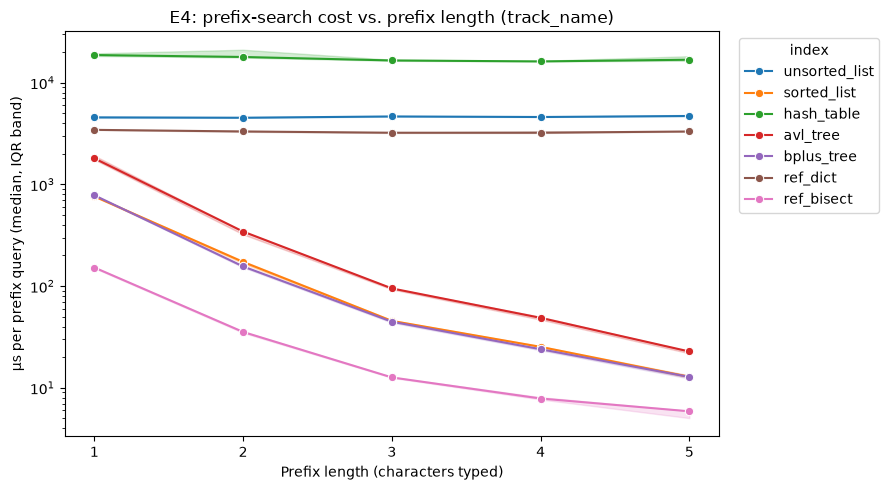

In [8]:
plt.figure(figsize=(9, 5))
sns.lineplot(data=e4, x="operation_param", y="us_per_op", hue="index_type",
             estimator="median", errorbar=("pi", 50), marker="o")
plt.yscale("log")
plt.xticks([1, 2, 3, 4, 5])
plt.xlabel("Prefix length (characters typed)")
plt.ylabel("µs per prefix query (median, IQR band)")
plt.title("E4: prefix-search cost vs. prefix length (track_name)")
plt.legend(title="index", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("e4_prefix.png", dpi=150)
plt.show()

In [9]:
rows = []
for idx, g in e4.groupby("index_type"):
    m = g.groupby("operation_param")["us_per_op"].median()
    slope, _ = np.polyfit(m.index, np.log10(m.values), 1)
    rows.append({"index": idx,
                 "log10_slope_per_char": round(slope, 2),
                 "speedup_per_extra_char": round(10 ** -slope, 1)})
pd.DataFrame(rows).sort_values("log10_slope_per_char")

,index,log10_slope_per_char,speedup_per_extra_char
0,avl_tree,-0.46,2.9
1,bplus_tree,-0.44,2.7
5,sorted_list,-0.44,2.7
3,ref_bisect,-0.35,2.2
2,hash_table,-0.01,1.0
4,ref_dict,-0.00,1.0
6,unsorted_list,0.00,1.0


In [10]:
(e4.groupby(["index_type", "operation_param"])[["comparisons_per_op", "nodes_visited_per_op", "us_per_op"]]
   .median().round(1).unstack("operation_param"))

comparisons_per_op                                          \
operation_param                1.0       2.0       3.0       4.0       5.0   
index_type                                                                   
avl_tree                    3660.7     642.6     185.0      92.5      40.7   
bplus_tree                  3669.8     648.8     192.1      99.2      47.8   
hash_table                 72396.0   72396.0   72396.0   72396.0   72396.0   
ref_bisect                     NaN       NaN       NaN       NaN       NaN   
ref_dict                       NaN       NaN       NaN       NaN       NaN   
sorted_list                 3660.5     642.6     184.6      92.0      40.2   
unsorted_list             113999.0  113999.0  113999.0  113999.0  113999.0   

                nodes_visited_per_op                                      \
operation_param                  1.0      2.0      3.0      4.0      5.0   
index_type                                                                 
avl_tree                      3660.7    642.6    185.0     92.5     40.7   
bplus_tree                     171.6     32.7     11.8      7.5      5.1   
hash_table                   97288.0  97288.0  97288.0  97288.0  97288.0   
ref_bisect                       NaN      NaN      NaN      NaN      NaN   
ref_dict                         NaN      NaN      NaN      NaN      NaN   
sorted_list                      0.0      0.0      0.0      0.0      0.0   
unsorted_list                    0.0      0.0      0.0      0.0      0.0   

                us_per_op                                      
operation_param       1.0      2.0      3.0      4.0      5.0  
index_type                                                     
avl_tree           1801.7    343.8     94.9     48.7     22.8  
bplus_tree          781.4    156.1     44.7     24.0     12.8  
hash_table        18692.8  17886.5  16528.4  16173.7  16811.5  
ref_bisect          152.3     35.4     12.7      7.9      5.9  
ref_dict           3435.8   3312.0   3218.8   3219.4   3310.9  
sorted_list         761.1    172.9     45.5     25.3     12.8  
unsorted_list      4559.7   4519.1   4653.7   4595.4   4700.2

In [12]:
def ratio(data, slow, fast):
    m = data.groupby(["operation_param", "index_type"])["us_per_op"].median().unstack()
    return (m[slow] / m[fast]).round(2)

pd.DataFrame({
    "sorted_list / ref_bisect":   ratio(e3, "sorted_list", "ref_bisect"),
    "avl_tree / bplus_tree":      ratio(e3, "avl_tree", "bplus_tree"),
    "hash_table / unsorted_list": ratio(e3, "hash_table", "unsorted_list"),
})

,sorted_list / ref_bisect,avl_tree / bplus_tree,hash_table / unsorted_list
operation_param,,,
0.0001,2.37,1.45,1.94
0.0010,2.33,2.08,1.29
0.0100,3.44,2.30,1.34
0.0500,3.24,2.43,1.38
0.1000,3.47,2.45,1.50
0.2500,4.14,2.42,1.64
